Cell 1 – Thư viện, kiểm tra GPU, cố định seed

In [1]:
import os, json, shutil, random, tarfile, datetime
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'KHÔNG CÓ – chọn Runtime → Change runtime type → T4 GPU')

SEED = 42
keras.utils.set_random_seed(SEED)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Cell 2 – Kết nối Google Drive, khai báo đường dẫn

In [2]:
from google.colab import drive
drive.mount('/content/drive')

ROOT      = '/content/drive/MyDrive/flower-classifier'
MODEL_DIR = f'{ROOT}/models'                       # các file giao cho phía web
CKPT_PATH = f'{ROOT}/checkpoints/best.keras'
SPLIT_ZIP = f'{ROOT}/data/tf_flowers_split.zip'    # bản chia train/val/test cố định
SPLIT_DIR = '/content/tf_flowers_split'

for d in [MODEL_DIR, f'{ROOT}/checkpoints', f'{ROOT}/data']:
    os.makedirs(d, exist_ok=True)

IMG_SIZE = (180, 180)
BATCH_SIZE = 32

Mounted at /content/drive


Cell 3 – Tải TF Flowers, chia cố định 70/15/15

In [ ]:
URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'

if os.path.exists(SPLIT_ZIP):
    shutil.rmtree(SPLIT_DIR, ignore_errors=True)
    shutil.unpack_archive(SPLIT_ZIP, SPLIT_DIR)
else:
    tgz = keras.utils.get_file('flower_photos.tgz', origin=URL)
    with tarfile.open(tgz) as tar:
        tar.extractall('/content', filter='data')
    src = '/content/flower_photos'
    classes = sorted(d for d in os.listdir(src) if os.path.isdir(f'{src}/{d}'))   # bỏ qua LICENSE.txt

    rng = random.Random(SEED)
    for cls in classes:
        files = sorted(os.listdir(f'{src}/{cls}'))
        rng.shuffle(files)
        n = int(len(files) * 0.15)
        parts = {'test': files[:n], 'val': files[n:2 * n], 'train': files[2 * n:]}
        for split, names in parts.items():
            os.makedirs(f'{SPLIT_DIR}/{split}/{cls}', exist_ok=True)
            for f in names:
                shutil.copy(f'{src}/{cls}/{f}', f'{SPLIT_DIR}/{split}/{cls}/{f}')
    shutil.make_archive(SPLIT_ZIP[:-4], 'zip', SPLIT_DIR)

counts = {split: {cls: len(os.listdir(f'{SPLIT_DIR}/{split}/{cls}'))
                  for cls in sorted(os.listdir(f'{SPLIT_DIR}/{split}'))}
          for split in ['train', 'val', 'test']}
print(json.dumps(counts, indent=2))

{
  "train": {
    "daisy": 445,
    "dandelion": 630,
    "roses": 449,
    "sunflowers": 491,
    "tulips": 561
  },
  "val": {
    "daisy": 94,
    "dandelion": 134,
    "roses": 96,
    "sunflowers": 104,
    "tulips": 119
  },
  "test": {
    "daisy": 94,
    "dandelion": 134,
    "roses": 96,
    "sunflowers": 104,
    "tulips": 119
  }
}


Cell 4 – Tạo tf.data, lưu class_names.json

In [ ]:
def load_split(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        f'{SPLIT_DIR}/{split}', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED)

train_ds = load_split('train', shuffle=True)
val_ds   = load_split('val',   shuffle=False)
test_ds  = load_split('test',  shuffle=False)
class_names = train_ds.class_names
print(class_names)

with open(f'{MODEL_DIR}/class_names.json', 'w') as f:
    json.dump(class_names, f)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

Found 2576 files belonging to 5 classes.
Found 547 files belonging to 5 classes.
Found 547 files belonging to 5 classes.
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


Cell 5 – Xây mô hình CNN

In [ ]:
model = keras.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1./255),
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomHue(0.1, value_range=(0, 1)),          # xoay sắc độ màu một chút (đỏ ↔ hồng ↔ cam)
    layers.RandomSaturation((0.3,0.7), value_range=(0, 1)),   # màu đậm/nhạt ngẫu nhiên
    layers.RandomGrayscale(0.2),                        # 20% ảnh thành trắng đen → phải nhìn hình dạng
    layers.Conv2D(16, 3, padding='same', activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'), layers.MaxPooling2D(),
    layers.Dropout(0.2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(class_names), activation='softmax'),
], name='flower_cnn')

model.summary()

Model: "flower_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 180, 180, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_hue (RandomHue)          │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_saturation               │ (None, 180, 180, 3)    │             0 │
│ (RandomSaturation)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_grayscale                │ (None, 180, 180, 3)    │             0 │
│ (RandomGrayscale)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 22, 22, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 15488)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,982,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,080,677 (7.94 MB)

 Trainable params: 2,080,677 (7.94 MB)

 Non-trainable params: 0 (0.00 B)

Cell 6 – Huấn luyện

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(CKPT_PATH, monitor='val_accuracy', save_best_only=True),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks)

model = keras.models.load_model(CKPT_PATH)   # dùng bản có val_accuracy tốt nhất

Epoch 1/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 18s 80ms/step - accuracy: 0.3560 - loss: 1.4782 - val_accuracy: 0.4296 - val_loss: 1.3707
Epoch 2/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.4608 - loss: 1.2800 - val_accuracy: 0.5430 - val_loss: 1.1116
Epoch 3/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.5120 - loss: 1.1862 - val_accuracy: 0.5722 - val_loss: 1.0264
Epoch 4/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.5268 - loss: 1.1652 - val_accuracy: 0.5740 - val_loss: 1.0693
Epoch 5/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.5501 - loss: 1.1254 - val_accuracy: 0.5503 - val_loss: 1.1187
Epoch 6/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.5757 - loss: 1.0853 - val_accuracy: 0.6033 - val_loss: 1.0037
Epoch 7/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.5870 - loss: 1.0370 - val_accuracy: 0.5923 - val_loss: 1.0333
Epoch 8/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.6258 - loss: 0.9782 - val_accuracy: 0.6764 - 

Cell 7 – Biểu đồ accuracy / loss theo epoch

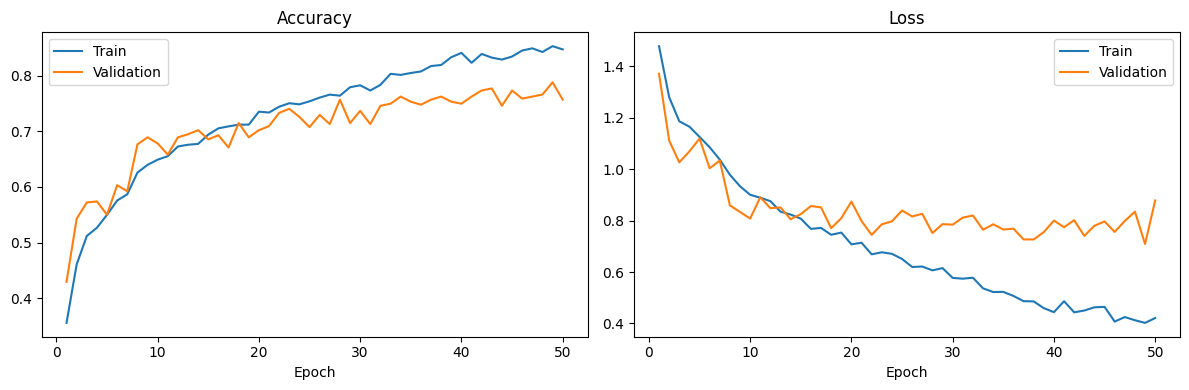

Epoch tốt nhất: 49/50 | train – val accuracy = 0.065


In [ ]:
h = history.history
ep = range(1, len(h['loss']) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(ep, h['accuracy'], label='Train'); plt.plot(ep, h['val_accuracy'], label='Validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(ep, h['loss'], label='Train'); plt.plot(ep, h['val_loss'], label='Validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/training_curves.png', dpi=150)
plt.show()

best_epoch = int(np.argmax(h['val_accuracy'])) + 1
gap = h['accuracy'][best_epoch - 1] - h['val_accuracy'][best_epoch - 1]
print(f'Epoch tốt nhất: {best_epoch}/{len(h["loss"])} | train – val accuracy = {gap:.3f}')
if gap > 0.15:
    print('⚠ Overfitting: tăng Dropout lên 0.3–0.4 hoặc tăng mức tăng cường dữ liệu')

Cell 8 – Đánh giá trên tập test, confusion matrix

Test accuracy = 0.7952
              precision    recall  f1-score   support

       daisy      0.849     0.777     0.811        94
   dandelion      0.897     0.784     0.837       134
       roses      0.635     0.760     0.692        96
  sunflowers      0.883     0.875     0.879       104
      tulips      0.738     0.782     0.759       119

    accuracy                          0.795       547
   macro avg      0.801     0.795     0.796       547
weighted avg      0.806     0.795     0.798       547



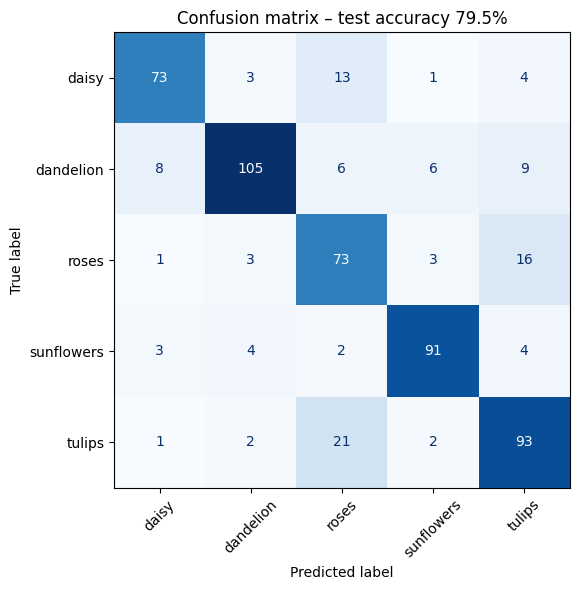

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f'Test accuracy = {test_acc:.4f}')
if test_acc < 0.65:
    print('⚠ Dưới 65%: thêm khối Conv2D(128), tăng epochs lên 30; vẫn thấp thì dùng MobileNetV2')

probs  = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
y_true = np.concatenate([y.numpy() for _, y in test_ds])

print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False)
plt.title(f'Confusion matrix – test accuracy {test_acc:.1%}')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/confusion_matrix.png', dpi=150)
plt.show()

Cell 9 – Xuất file cho web và kiểm tra nạp lại

In [ ]:
model.save(f'{MODEL_DIR}/flower_cnn.keras')

model_info = {
    'version': 'v1',
    'uncertain_threshold': 0.5,
    'charts': {'training_curves': '/static/model/training_curves.png',
               'confusion_matrix': '/static/model/confusion_matrix.png'},
    'img_size': list(IMG_SIZE),
    'class_names': class_names,
    'num_images': counts,
    'test_accuracy': round(float(test_acc), 4),
    'per_class': {c: {'precision': round(report[c]['precision'], 4),
                      'recall':    round(report[c]['recall'], 4),
                      'f1':        round(report[c]['f1-score'], 4)} for c in class_names},
    'epochs_trained': len(h['loss']),
    'best_epoch': best_epoch,
    'trained_at': datetime.date.today().isoformat(),
    'tensorflow_version': tf.__version__,
}
with open(f'{MODEL_DIR}/model_info.json', 'w', encoding='utf-8') as f:
    json.dump(model_info, f, ensure_ascii=False, indent=2)

# Kiểm tra file .keras nạp lại được và cho kết quả giống hệt
loaded = keras.models.load_model(f'{MODEL_DIR}/flower_cnn.keras')
print('Chênh lệch sau khi nạp lại:', np.abs(loaded.predict(test_ds, verbose=0) - probs).max())

for f in sorted(os.listdir(MODEL_DIR)):
    print(f'{f:22} {os.path.getsize(f"{MODEL_DIR}/{f}") / 1e6:.1f} MB')

Chênh lệch sau khi nạp lại: 0.0
class_names.json       0.0 MB
confusion_matrix.png   0.1 MB
flower_cnn.keras       25.0 MB
model_info.json        0.0 MB
training_curves.png    0.1 MB


Cell 10 – Thử phân loại 1 ảnh ngoài bộ dữ liệu

Saving images (10).jpg to images (10).jpg
Kết quả: roses (64.4%)
Top 3  : roses 64.4%, dandelion 24.9%, daisy 5.4%


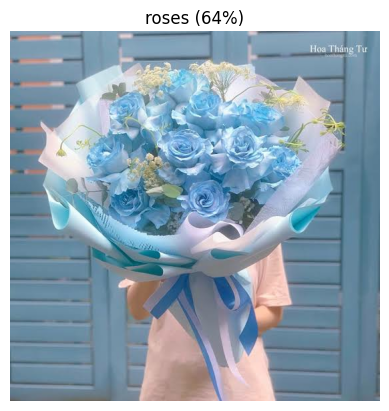

In [3]:
from google.colab import files

model_test = keras.models.load_model(f'{MODEL_DIR}/flower_cnn.keras')
with open(f'{MODEL_DIR}/class_names.json') as f:
    names = json.load(f)

fname, data = next(iter(files.upload().items()))   # chọn 1 ảnh JPG/PNG

img = tf.io.decode_image(data, channels=3, expand_animations=False)
p = model_test.predict(tf.image.resize(img, IMG_SIZE)[tf.newaxis], verbose=0)[0]
top3 = p.argsort()[::-1][:3]

print(f'Kết quả: {names[top3[0]]} ({p[top3[0]]:.1%})')
print('Top 3  :', ', '.join(f'{names[i]} {p[i]:.1%}' for i in top3))

plt.imshow(img.numpy())
plt.title(f'{names[top3[0]]} ({p[top3[0]]:.0%})')
plt.axis('off')
plt.show()